# 06.3 · How many clusters? Elbow, silhouette, and profiling clusters

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/03-choosing-k/lesson.ipynb)

Read the [README](README.md) and compute the silhouette of D on paper first. This notebook:

1. Checks the by-hand silhouette and Davies-Bouldin on the eight customers.
2. Scans $k = 2 \dots 8$ on all ShopWave customers with three metrics.
3. Profiles the candidates, names four personas, and checks them.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. The eight customers from 06.2

In [2]:
names = list("ABCDEFGH")
points = np.array([[1, 1], [1, 3], [2, 2], [4, 3], [6, 6], [7, 5], [7, 8], [9, 7]], dtype=float)
labels = np.array([0, 0, 0, 0, 1, 1, 1, 1])            # final clusters from 06.2

### Silhouette of D, step by step

In [3]:
D = points[3]
dist = np.linalg.norm(points - D, axis=1)                  # distance from D to everyone
a = dist[[0, 1, 2]].mean()                                 # own cluster: A, B, C
b = dist[[4, 5, 6, 7]].mean()                              # other cluster: E, F, G, H
print("distances from D:", {n: float(v) for n, v in zip(names, dist.round(3))})
print(f"a = {a:.3f}   b = {b:.3f}   s(D) = (b - a) / max(a, b) = {(b - a) / max(a, b):.3f}")

distances from D: {'A': 3.606, 'B': 3.0, 'C': 2.236, 'D': 0.0, 'E': 3.606, 'F': 3.606, 'G': 5.831, 'H': 6.403}
a = 2.947   b = 4.861   s(D) = (b - a) / max(a, b) = 0.394


In [4]:
from sklearn.metrics import silhouette_samples, silhouette_score, davies_bouldin_score

print("silhouette per customer:", {n: float(v) for n, v in zip(names, silhouette_samples(points, labels).round(3))})
print(f"average silhouette: {silhouette_score(points, labels):.3f}")

silhouette per customer: {'A': 0.721, 'B': 0.704, 'C': 0.758, 'D': 0.394, 'E': 0.59, 'F': 0.58, 'G': 0.675, 'H': 0.677}
average silhouette: 0.637


D is the least comfortable member (0.394); C, in the middle of its cluster, is the most (0.758).

### Davies-Bouldin, step by step

In [5]:
cents = np.array([points[labels == j].mean(axis=0) for j in range(2)])
spread = [np.linalg.norm(points[labels == j] - cents[j], axis=1).mean() for j in range(2)]
gap = np.linalg.norm(cents[0] - cents[1])
print(f"s1 = {spread[0]:.3f}   s2 = {spread[1]:.3f}   distance between centroids = {gap:.3f}")
print(f"DB by hand = {(spread[0] + spread[1]) / gap:.4f}")
print(f"DB sklearn = {davies_bouldin_score(points, labels):.4f}")

s1 = 1.309   s2 = 1.552   distance between centroids = 6.755
DB by hand = 0.4236
DB sklearn = 0.4236


### The elbow on eight customers

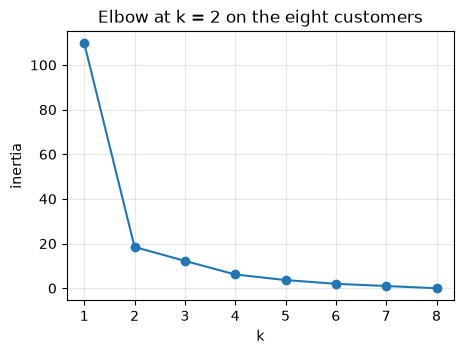

[109.75, 18.5, 12.25, 6.17, 3.67, 2.0, 1.0, 0.0]


In [6]:
from sklearn.cluster import KMeans
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(points).inertia_ for k in range(1, 9)]
plt.figure(figsize=(5, 3.5))
plt.plot(range(1, 9), inertias, marker="o")
plt.xlabel("k"); plt.ylabel("inertia"); plt.title("Elbow at k = 2 on the eight customers")
plt.grid(alpha=.3); plt.show()
print([round(i, 2) for i in inertias])

## 2. All ShopWave customers

The RFM table from 06.1, logged and standardised.

In [7]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [8]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_)})
scores = pd.DataFrame(rows).set_index("k")
scores.round(3)

,inertia,silhouette,davies_bouldin
k,,,
2,6487.979,0.434,0.892
3,4879.094,0.338,1.048
4,3962.719,0.337,1.013
5,3331.834,0.316,0.995
6,2875.394,0.314,1.020
7,2573.151,0.309,0.977
8,2359.543,0.302,0.993


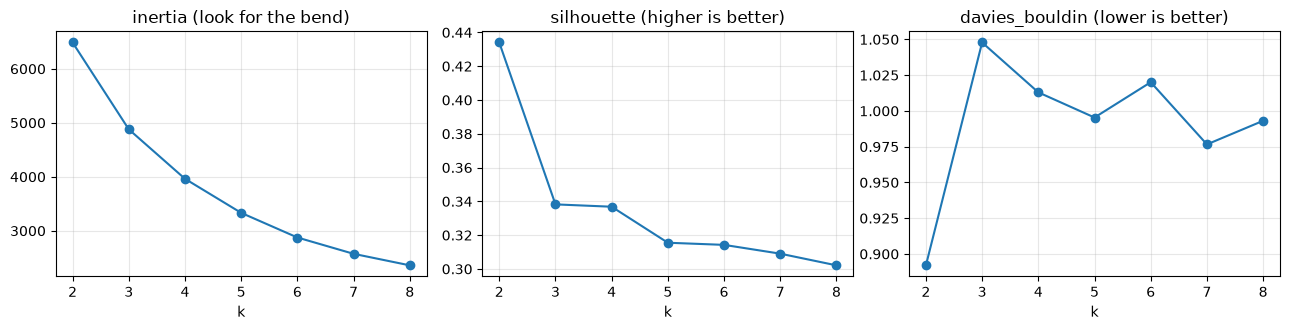

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, note in zip(axes, scores.columns, ["look for the bend", "higher is better", "lower is better"]):
    ax.plot(scores.index, scores[col], marker="o")
    ax.set_title(f"{col} ({note})"); ax.set_xlabel("k"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Silhouette and Davies-Bouldin both point at $k = 2$. The elbow is a gentle bend somewhere around 3–4. Real customers form one continuous cloud, not separate blobs, so the metrics cannot settle it alone. Look at what the options *mean*.

## 3. Profiles

In [11]:
def profile(labels):
    """Size, mean R/F/M and revenue share per cluster, sorted by mean spend."""
    p = rfm.assign(cluster=labels).groupby("cluster").agg(
        customers=("recency", "size"), recency=("recency", "mean"),
        frequency=("frequency", "mean"), monetary=("monetary", "mean"))
    p["revenue_share"] = rfm.groupby(labels)["monetary"].sum() / rfm["monetary"].sum()
    return p.sort_values("monetary", ascending=False)

In [12]:
labels2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
profile(labels2).round(2)

,customers,recency,frequency,monetary,revenue_share
cluster,,,,,
0,1652,25.34,8.49,4570.04,0.85
1,2686,133.10,1.68,497.96,0.15


Two groups: "active" and "inactive". Correct, and already known. It does not give marketing four different things to do.

In [13]:
labels4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X)
p4 = profile(labels4)
p4.insert(0, "persona", ["Champions", "Regulars, cooling", "Newcomers", "Lapsed one-timers"])
p4.round(2)

,persona,customers,recency,frequency,monetary,revenue_share
cluster,,,,,,
0,Champions,699,11.37,13.88,8194.29,0.64
3,"Regulars, cooling",1178,69.95,4.14,1814.50,0.24
2,Newcomers,826,17.28,2.18,555.82,0.05
1,Lapsed one-timers,1635,180.27,1.32,344.24,0.06


The `persona` names are assigned in order of mean spend, after reading the numbers:

- **Champions**: bought ~11 days ago, ~14 orders, ~£8,200 each. About two thirds of revenue from one sixth of customers.
- **Regulars, cooling**: ~4 orders and ~£1,800, but last order ~70 days ago. Worth a nudge before they lapse.
- **Newcomers**: bought recently (~17 days) but only about twice and ~£560. Still deciding whether ShopWave is for them.
- **Lapsed one-timers**: one order about six months ago. The largest group, the smallest revenue.

### Checking the choice

Silhouette per customer, by persona. Values below 0 are customers who sit closer to another persona than to their own.

In [14]:
persona_of = dict(zip(p4.index, p4["persona"]))
sil = pd.DataFrame({"persona": pd.Series(labels4).map(persona_of), "s": silhouette_samples(X, labels4)})
summary = sil.groupby("persona")["s"].agg(mean="mean", negative=lambda s: (s < 0).mean())
print(summary.round(3))
print(f"\nall customers: mean silhouette {sil['s'].mean():.3f}, negative {(sil['s'] < 0).mean():.1%}")

                    mean  negative
persona                           
Champions          0.298     0.076
Lapsed one-timers  0.419     0.000
Newcomers          0.256     0.031
Regulars, cooling  0.302     0.008

all customers: mean silhouette 0.337, negative 2.0%


Only about 2% of customers would rather be in another group. With 06.1's stability check (ARI ≈ 0.97 across seeds) and four groups that each get a different action, **four is the defensible choice**, even though two scores higher.

## Quiz answers

1. Inertia **always** falls as $k$ grows and reaches 0 when every point is its own cluster, so "lowest" always means "as many clusters as points".
2. $a(i)$: average distance to the other points in $i$'s own cluster. $b(i)$: average distance to the points of the nearest other cluster.
3. It is, on average, **closer to another cluster** than to its own: probably assigned to the wrong group, or sitting on a border.
4. **Lower** is better.
5. Real customers form a continuous cloud, so the metrics favour the crude active/inactive split. Four groups were almost as good on the metrics, stable across seeds, and each gave marketing a **different action**. Usefulness decides.

**Next:** [06.4 Hierarchical clustering](../04-hierarchical/)